# 3. Много признаков и много рядов

В ноутбуках 1–2 мы подбирали признаки вручную для одного ряда. На практике возникают
два вопроса масштаба:

1. **Много признаков.** Что будет, если добавить всё подряд, и спасают ли регуляризация и
   автоматический отбор.
2. **Много рядов.** Одна модель на каждый ряд или одна на всех, и как глобальной модели
   различать ряды (групповые признаки).

In [1]:
import common  # первым: глушит предупреждения ETNA при импорте

common.quiet()

import numpy as np  # noqa: E402
import pandas as pd  # noqa: E402
from etna.models import ElasticPerSegmentModel, LinearMultiSegmentModel, LinearPerSegmentModel  # noqa: E402
from etna.transforms import (  # noqa: E402
    DateFlagsTransform,
    FilterFeaturesTransform,
    FourierTransform,
    HolidayTransform,
    LagTransform,
    LinearTrendTransform,
    LogTransform,
    MeanEncoderTransform,
    MeanSegmentEncoderTransform,
    MeanTransform,
    OneHotEncoderTransform,
    SegmentEncoderTransform,
    StandardScalerTransform,
    TreeFeatureSelectionTransform,
)

## 1. Регуляризация и отбор признаков

Чем больше признаков, тем лучше модель описывает **обучающую выборку**, но она может
начать подстраиваться под случайный шум вместо закономерностей. Это называется **переобучение**.
Симптом: хорошее качество на истории, но плохое на прогнозе. Автоматических средств два:

- **регуляризация** — штраф за большие коэффициенты (`ElasticPerSegmentModel`). Перед ней
  признаки нужно привести к одному масштабу (`StandardScalerTransform`), иначе штраф
  действует на них неодинаково;
- **отбор признаков** — оставить только самые полезные (`TreeFeatureSelectionTransform`).

### Маленький набор признаков

Референс из ноутбуков 1–2, собранный вручную: тренд + день недели + годовые гармоники
(`order=3`) + праздники + 10 предновогодних дней + сезонные лаги и окна.

In [2]:
HORIZON = 14
onion = common.load_onion(new_year_days=10)
lag_col = f"lag_{HORIZON}"


def n_features(result: dict) -> int:
    """Сколько признаков реально получила модель."""
    return len(result["pipelines"][0].model._models["onion"].regressor_columns)


small = [
    LinearTrendTransform(in_column="target"),
    *common.dow(),
    FourierTransform(period=365.25, order=3, out_column="f365"),
    HolidayTransform(iso_code="RUS", out_column="holiday"),
    LagTransform(in_column="target", lags=[14, 21, 28, 35, 364], out_column="lag"),
    MeanTransform(in_column=lag_col, window=7, out_column="mean7"),
    MeanTransform(in_column=lag_col, window=28, out_column="mean28"),
]
results = {"маленький набор": common.backtest(LinearPerSegmentModel(), small, onion, HORIZON)}
print("признаков:", n_features(results["маленький набор"]))
common.compare(results)

признаков: 31


,WAPE,MAE
маленький набор,0.0547,3668.3156


### Большой набор

Тот же набор, но увеличим порядки Фурье (20 для года, 5 для месяца) и добавим 30 лагов.
На обучении это даст более точное приближение, но рисков много:
- высокие гармоники ловят шум;
- много лагов → мультиколлинеарность (лаги 14 и 15 сильно коррелированы).

In [3]:
big = [
    LinearTrendTransform(in_column="target"),
    *common.dow(),
    FourierTransform(period=365.25, order=20, out_column="f365"),
    FourierTransform(period=30.44, order=5, out_column="f30"),
    HolidayTransform(iso_code="RUS", out_column="holiday"),
    LagTransform(in_column="target", lags=list(range(14, 43)) + [364], out_column="lag"),
    MeanTransform(in_column=lag_col, window=7, out_column="mean7"),
    MeanTransform(in_column=lag_col, window=28, out_column="mean28"),
]
results["большой набор (OLS)"] = common.backtest(LinearPerSegmentModel(), big, onion, HORIZON)
print("признаков:", n_features(results["большой набор (OLS)"]))
common.compare(results)

признаков: 100


,WAPE,MAE
маленький набор,0.0547,3668.3156
большой набор (OLS),0.0975,6465.5792


Ошибка выросла почти вдвое: модель переобучилась. Высокие гармоники ловят шум, а соседние
лаги (14, 15, 16…) почти одинаковы — коэффициенты при них нестабильны (мультиколлинеарность).

### Регуляризация: Ridge / Lasso / ElasticNet

`ElasticPerSegmentModel` — это регрессия с штрафом за большие коэффициенты:
- `l1_ratio=0` — Ridge (L2-штраф), сжимает все коэффициенты, но не обнуляет;
- `l1_ratio=1` — Lasso (L1-штраф), часть коэффициентов обнуляет → отбор признаков;
- `l1_ratio ∈ (0, 1)` — ElasticNet, комбинация обоих.

`alpha` — сила штрафа (0 = обычный МНК, ∞ = все коэффициенты в ноль). Масштабирование
обязательно: если один признак меняется от 0 до 1, а другой — от 0 до 1000, штраф на них
несопоставим.

In [4]:
for alpha, l1_ratio in [(0.01, 0.0), (0.1, 0.0), (0.01, 1.0), (0.1, 1.0)]:
    name = f"{'Ridge' if l1_ratio == 0 else 'Lasso'}, alpha={alpha}"
    results[name] = common.backtest(
        ElasticPerSegmentModel(alpha=alpha, l1_ratio=l1_ratio, max_iter=20000),
        big + [StandardScalerTransform(in_column=None)],
        onion,
        HORIZON,
    )
    coef = results[name]["pipelines"][0].model._models["onion"].model.coef_
    print(f"{name}: ненулевых коэффициентов {(abs(coef) > 1e-8).sum()} из {coef.size}")
common.compare(results)

Ridge, alpha=0.01: ненулевых коэффициентов 100 из 100


Ridge, alpha=0.1: ненулевых коэффициентов 100 из 100


Lasso, alpha=0.01: ненулевых коэффициентов 71 из 100


Lasso, alpha=0.1: ненулевых коэффициентов 10 из 100


,WAPE,MAE
маленький набор,0.0547,3668.3156
большой набор (OLS),0.0975,6465.5792
"Ridge, alpha=0.01",0.0859,5688.1885
"Ridge, alpha=0.1",0.0823,5436.9730
"Lasso, alpha=0.01",0.0815,5621.7351
"Lasso, alpha=0.1",0.1091,7981.8862


Регуляризация заметно исправляет большой набор (0.098 → ~0.082), но **до ручного маленького
набора не дотягивает**. Lasso при `alpha=0.01` сам выбросил около трети признаков; при
`alpha=0.1` он обнуляет почти всё, включая полезное, и качество падает. Значит, `alpha`
нужно подбирать на бэктесте, как любой гиперпараметр.

### Отбор признаков деревом

`TreeFeatureSelectionTransform` обучает случайный лес, ранжирует признаки по важности и
оставляет `top_k` лучших.

In [5]:
for k in (10, 20):
    results[f"отбор деревом, top {k}"] = common.backtest(
        LinearPerSegmentModel(),
        big + [TreeFeatureSelectionTransform(model="random_forest", top_k=k)],
        onion,
        HORIZON,
    )
print("top 10:", sorted(results["отбор деревом, top 10"]["pipelines"][0].model._models["onion"].regressor_columns))
common.compare(results)

top 10: ['f365_1', 'f365_10', 'f365_2', 'f365_3', 'f365_4', 'f365_6', 'lag_14', 'lag_364', 'mean28', 'mean7']


,WAPE,MAE
маленький набор,0.0547,3668.3156
большой набор (OLS),0.0975,6465.5792
"Ridge, alpha=0.01",0.0859,5688.1885
"Ridge, alpha=0.1",0.0823,5436.9730
"Lasso, alpha=0.01",0.0815,5621.7351
"Lasso, alpha=0.1",0.1091,7981.8862
"отбор деревом, top 10",0.1190,8747.2235
"отбор деревом, top 20",0.1218,8693.2061


Отбор деревом здесь проигрывает даже большому набору без регуляризации. Посмотрите, что
лес оставил: лаги, гармоники и окна — и **ни дня недели, ни предновогодних дней**. Важность
в лесу считается по вкладу в его собственные разбиения: дерево легко «собирает» день недели
из лагов, а редкие события (10 дней в году) почти не дают ему выигрыша. Для линейной модели
же это ключевые признаки. Отбор по нелинейной модели не обязательно хорош для линейной.

**Выводы.**
- Больше признаков ≠ лучше прогноз. Признаки, осмысленно подобранные по структуре ряда,
  выиграли у всех автоматических способов.
- Если признаков много, регуляризация (Ridge/Lasso + `StandardScalerTransform`) — надёжная
  страховка от переобучения; её силу (`alpha`) подбирают на бэктесте.
- Автоматический отбор проверяйте бэктестом и смотрите, **что** он выбросил.
  В ETNA есть и другие отборщики: `MRMRFeatureSelectionTransform` (релевантность минус
  избыточность), `GaleShapleyFeatureSelectionTransform`, `FilterFeaturesTransform` (вручную).

## 2. Групповые признаки: одна модель на много рядов

До сих пор мы обучали **локальную** модель: своя регрессия на каждый ряд
(`LinearPerSegmentModel`). Когда рядов много, а истории у части из них мало (новые магазины,
новые товары), локальной модели не на чем учиться. **Глобальная** модель
(`LinearMultiSegmentModel`) обучается сразу на всех рядах: общие закономерности
(недельный рисунок, сезон) оцениваются по всей панели.

Цена — модель перестаёт различать ряды. Чтобы вернуть ей индивидуальность, нужны
**групповые признаки**: идентификатор ряда, его средний уровень, статические свойства.

### Учебная панель: 30 магазинов, половина открылась недавно

У всех магазинов один и тот же недельный и месячный рисунок продаж (декабрь — пик), но
разный уровень. 15 «старых» магазинов работают два года, 15 «новых» открылись осенью
последнего года — у них всего несколько недель истории и ни одного декабря.

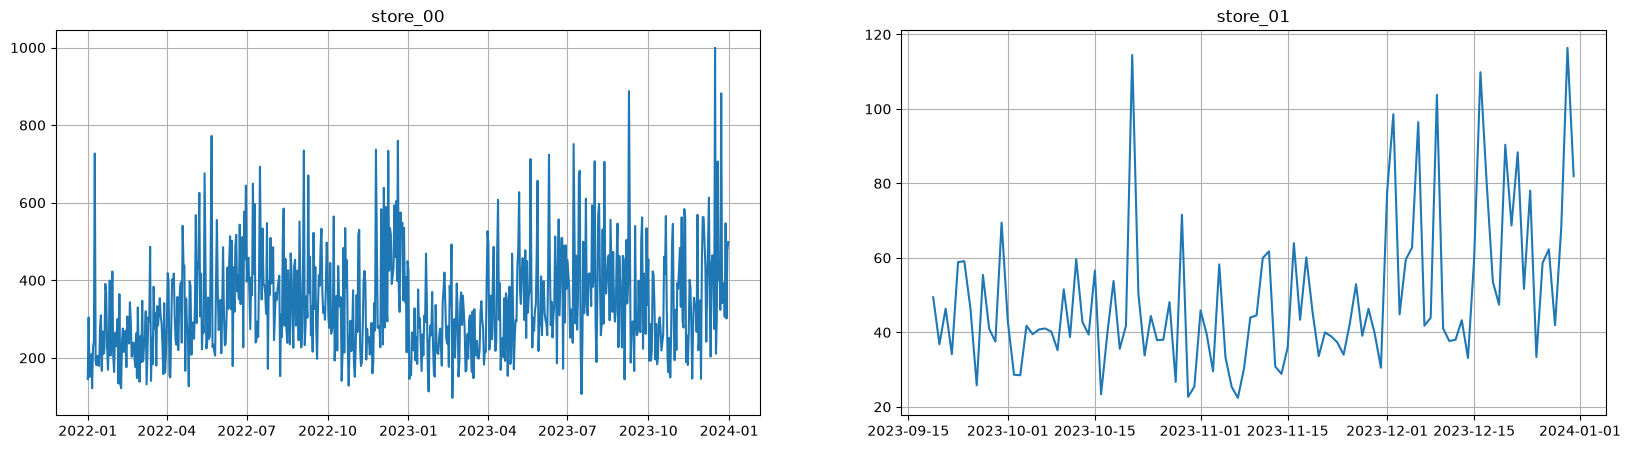

In [6]:
rng = np.random.default_rng(3)
dates = pd.date_range("2022-01-01", "2023-12-31", freq="D")
weekly = np.array([0.8, 0.9, 1.0, 1.0, 1.1, 1.4, 1.2])[dates.dayofweek]
monthly = np.array([0.8, 0.8, 0.9, 1.0, 1.1, 1.2, 1.3, 1.3, 1.1, 1.0, 1.0, 1.5])[dates.month - 1]
opening_of_new = pd.Timestamp("2023-09-19")

stores = []
for i in range(30):
    sales = rng.lognormal(4, 0.8) * weekly * monthly * np.exp(rng.normal(0, 0.3, dates.size))
    store = pd.DataFrame({"timestamp": dates, "segment": f"store_{i:02d}", "target": sales})
    stores.append(store[store["timestamp"] >= opening_of_new] if i % 2 else store)
panel = common.make_ts(pd.concat(stores))
new_stores = [f"store_{i:02d}" for i in range(1, 30, 2)]
panel.plot(segments=["store_00", "store_01"])

Модель во всех вариантах одна: логарифм продаж (мультипликативные эффекты становятся
аддитивными) + день недели + месяц. Меняем только то, как модель видит ряды.
Горизонт — 28 дней.

In [7]:
month = [
    DateFlagsTransform(
        day_number_in_week=False, day_number_in_month=False, is_weekend=False, month_number_in_year=True, out_column="m"
    ),
    OneHotEncoderTransform(in_column="m_month_number_in_year", out_column="month"),
    FilterFeaturesTransform(exclude=["m_month_number_in_year"]),
]
panel_calendar = [LogTransform(in_column="target"), *common.dow(), *month]

variants = {
    "локальная": (LinearPerSegmentModel(), panel_calendar),
    "глобальная, без признаков ряда": (LinearMultiSegmentModel(), panel_calendar),
    "глобальная + one-hot сегмента": (
        LinearMultiSegmentModel(),
        panel_calendar
        + [SegmentEncoderTransform(), OneHotEncoderTransform(in_column="segment_code", out_column="segment")],
    ),
    "глобальная + средний уровень ряда": (LinearMultiSegmentModel(), panel_calendar + [MeanSegmentEncoderTransform()]),
}
rows = {}
for name, (model, transforms) in variants.items():
    metrics = common.backtest(model, transforms, panel, horizon=28)["metrics"]
    is_new = metrics["segment"].isin(new_stores)
    rows[name] = {"WAPE новые": metrics[is_new]["WAPE"].mean(), "WAPE старые": metrics[~is_new]["WAPE"].mean()}
pd.DataFrame(rows).T.round(4)

,WAPE новые,WAPE старые
локальная,0.2804,0.2452
"глобальная, без признаков ряда",0.5874,0.6248
глобальная + one-hot сегмента,0.2377,0.2421
глобальная + средний уровень ряда,0.2389,0.2425


- **Локальная** модель на старых магазинах работает нормально, а на новых хуже: за
  несколько недель истории не оценить ни месячный эффект, ни декабрьский пик.
- **Глобальная без признаков ряда** проваливается везде: для неё все магазины одинаковые,
  и она прогнозирует всем средний по панели уровень.
- **Глобальная с признаком ряда** лучше обеих: календарные коэффициенты общие и оценены по
  всей панели (декабрь видели старые магазины), а уровень у каждого свой.

### Какой признак ряда выбрать

- `SegmentEncoderTransform` даёт номер сегмента `segment_code`. Номер — категория, а не
  число: для линейной модели его нужно развернуть в one-hot (по признаку на ряд).
- `MeanSegmentEncoderTransform` — **target encoding**: среднее значение `target` ряда по
  истории (расширяющееся среднее, сдвинутое так, чтобы текущая точка не попадала в своё
  среднее). Один признак вместо сотни one-hot, и для нового ряда он считается сразу.
- `MeanEncoderTransform` — то же для любого категориального признака (например, среднее
  по категории товара или по региону).
- Статические свойства ряда (тип магазина, город, кластер) передаются через `df_exog`
  как обычные known-future признаки и кодируются one-hot.

### Категория вместо номера ряда

Признак ряда не обязан быть уникальным для магазина. Часто есть **общая категория** —
тип точки, формат, регион, — и магазинов в категории много. Тогда есть два варианта:
развернуть категорию в one-hot или заменить её средним `target` по категории.

Добавим магазинам тип: 0, 1 или 2 — три группы с разным уровнем (36, 60 и 160 в среднем).
Тип передаётся через `df_exog` как обычный known-future признак.

In [8]:
raw_panel = pd.concat(stores)
segments = sorted(raw_panel["segment"].unique())
levels = raw_panel.groupby("segment")["target"].mean()
kind = {segment: min(rank * 3 // len(segments), 2) for rank, segment in enumerate(levels.sort_values().index)}
kind_exog = pd.DataFrame(
    [
        (timestamp, segment, kind[segment])
        for segment in segments
        for timestamp in pd.date_range(dates.min(), dates.max() + pd.Timedelta(days=60))
    ],
    columns=["timestamp", "segment", "kind"],
)
panel_kind = common.make_ts(raw_panel, exog=kind_exog)

print(raw_panel.assign(kind=raw_panel["segment"].map(kind)).groupby("kind")["target"].agg(["count", "mean"]).round(0).to_string())

encoders = {
    "глобальная + one-hot сегмента": (panel, [SegmentEncoderTransform(), OneHotEncoderTransform(in_column="segment_code", out_column="segment_x")]),
    "глобальная + one-hot типа": (panel_kind, [OneHotEncoderTransform(in_column="kind", out_column="kind_x"), FilterFeaturesTransform(exclude=["kind"])]),
    "глобальная + mean encoder по типу": (panel_kind, [MeanEncoderTransform(in_column="kind", out_column="kind_mean")]),
}
encoder_rows = {}
for name, (ts, extra) in encoders.items():
    metrics = common.backtest(LinearMultiSegmentModel(), panel_calendar + extra, ts, horizon=28)["metrics"]
    is_new = metrics["segment"].isin(new_stores)
    encoder_rows[name] = {
        "WAPE новые": metrics[is_new]["WAPE"].mean(),
        "WAPE старые": metrics[~is_new]["WAPE"].mean(),
    }
pd.DataFrame(encoder_rows).T.round(4)

      count   mean
kind              
0      4170   36.0
1      3544   60.0
2      4796  160.0


,WAPE новые,WAPE старые
глобальная + one-hot сегмента,0.2377,0.2421
глобальная + one-hot типа,0.3128,0.3328
глобальная + mean encoder по типу,0.2390,0.2423


`MeanEncoderTransform` даёт **один** числовой признак вместо трёх one-hot и работает
практически так же (0.2390 против 0.2377). А вот one-hot по типу — заметно хуже (0.3128):
внутри типа разброс уровней большой, и общий на тип коэффициент не описывает отдельный
магазин. Категория полезна как **признак уровня**, но заменить индивидуальность ряда
не может — для этого нужен `MeanSegmentEncoderTransform` или номер сегмента.

Практическое правило: чем крупнее категория, тем дешевле её кодировать средним; чем
ближе категория к «один ряд = одна категория», тем важнее сохранить индивидуальность.

**Риск утечки.** Target encoding, посчитанный по всей истории, включая период, который мы
прогнозируем, «подсказывает» модели ответ. В ETNA энкодеры обучаются внутри фолдов бэктеста
только на обучающей части, поэтому оценка честная; при ручном расчёте это нужно
контролировать самому.